**Mexico: IMF report to dashboard**

This notebook uses IMF Country Report No. 25/301. Choose Run all. Saved replies mean a rerun makes no new model calls.

**Which report**

I used 25/301 because it is the latest staff report in my allocation.

**0.1 Packages**

This installs pypdf, faiss-cpu, pytesseract and Tesseract. The versions are fixed so the text stays the same.

In [1]:
import importlib.metadata as im
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "pypdf==6.21.4", "faiss-cpu==1.15.1", "pytesseract==0.3.13"], check=True)
    subprocess.run("apt-get -qq install -y tesseract-ocr > /dev/null", shell=True, check=True)

print({p: im.version(p) for p in ("pypdf", "faiss-cpu", "pytesseract", "sentence-transformers",
                                  "transformers", "pandas", "numpy", "matplotlib", "seaborn", "pydantic")})

{'pypdf': '6.21.4', 'faiss-cpu': '1.15.1', 'pytesseract': '0.3.13', 'sentence-transformers': '5.7.0', 'transformers': '5.22.0', 'pandas': '2.2.3', 'numpy': '2.4.6', 'matplotlib': '3.10.0', 'seaborn': '0.13.2', 'pydantic': '2.14.1'}


**0.2 Settings**

Every setting is in one place, and each step saves its result as JSON.

In [2]:
import functools
import hashlib
import json
import logging
import os
import re
import time
import warnings
from pathlib import Path
from types import SimpleNamespace
from typing import Literal, Optional, TypedDict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pydantic import BaseModel, Field, ValidationError

os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")   # keep model-download bars out of the saved outputs

CFG = SimpleNamespace(
    country="Mexico",
    report="IMF Country Report No. 25/301 (FCL request staff report, 29 Oct 2025)",
    pdf="mexico_cr25301.pdf",
    pdf_source="https://www.elibrary.imf.org/view/journals/002/2025/301/002.2025.issue-301-en.xml",
    repo_url="",                                   # public GitHub repo; on Colab its data/ and cache/ are cloned
    backend=os.environ.get("MEXICO_LLM", "auto"),  # auto | colab | gemini_api | replay
    writer="google/gemini-3.8-flash",              # extraction and summaries
    judge="google/gemini-3.1-pro-preview",         # a different, larger model marks the writer's work
    embedder="sentence-transformers/all-mpnet-base-v2",
    chunk_tokens=360,    # mpnet reads at most 384 tokens, so a chunk is never cut off when it is embedded
    overlap=50,
    top_k=6,
    summary_words=100,   # brief: each section summary under 100 words
    max_tokens=4096,     # output cap sent with every Colab call (see 0.3)
    retries=4,
    dpi=300,
)

ROOT = Path.cwd()
if IN_COLAB and CFG.repo_url and not (ROOT / "data" / CFG.pdf).exists():
    subprocess.run(["git", "clone", "-q", CFG.repo_url, "repo"], check=True)
    os.chdir("repo")
    ROOT = Path.cwd()
DATA, CACHE, OUT_JSON, OUT_FIG = (ROOT / p for p in ("data", "cache", "outputs/json", "outputs/figures"))
for folder in (DATA, CACHE, OUT_JSON, OUT_FIG):
    folder.mkdir(parents=True, exist_ok=True)


def strict(obj):
    """JSON has no NaN: turn NaN and numpy scalars into plain values so json.dumps(allow_nan=False) passes."""
    if isinstance(obj, dict):
        return {str(k): strict(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [strict(v) for v in obj]
    if isinstance(obj, np.generic):
        obj = obj.item()
    if isinstance(obj, float) and obj != obj:
        return None
    return obj


def write_json(obj, name: str) -> Path:
    path = OUT_JSON / name
    path.write_text(json.dumps(strict(obj), indent=2, ensure_ascii=False, allow_nan=False, default=str),
                    encoding="utf-8")
    return path


LEDGER: list[dict] = []   # one row per finished step: file written, seconds, size


def checkpoint(filename: str):
    """Decorator: run the step, save what it returns to outputs/json/<filename>, log it in LEDGER."""
    def wrap(step):
        @functools.wraps(step)
        def run(*args, **kwargs):
            t0 = time.perf_counter()
            result = step(*args, **kwargs)
            payload = result.to_dict("records") if isinstance(result, pd.DataFrame) else result
            write_json(payload, filename)
            LEDGER.append({"step": step.__name__, "file": filename, "seconds": round(time.perf_counter() - t0, 2),
                           "items": len(payload) if hasattr(payload, "__len__") else 1})
            return result
        return run
    return wrap


print("Working in", ROOT, "| backend setting:", CFG.backend)

Working in /content | backend setting: auto


**0.3 Model calls**

All model calls go through one function, and every reply is saved.

In [3]:
def gemini_key() -> Optional[str]:
    if IN_COLAB:
        try:
            from google.colab import userdata
            return userdata.get("GEMINI_API_KEY")
        except Exception:
            return None
    return os.environ.get("GEMINI_API_KEY")


def choose_backend(setting: str) -> str:
    if setting != "auto":
        return setting
    if gemini_key():
        return "gemini_api"
    try:
        from google.colab import ai  # noqa: F401  (Colab's built-in Gemini, no key needed)
        return "colab"
    except ImportError:
        return "replay"


BACKEND = choose_backend(CFG.backend)
CACHE_FILE = CACHE / "llm_cache.json"
MEMO: dict = json.loads(CACHE_FILE.read_text(encoding="utf-8")) if CACHE_FILE.exists() else {}
CALL_LOG: list[dict] = []


class NotCached(RuntimeError):
    """Replay mode met a prompt that has no stored reply."""


def live_call(model: str, system: str, prompt: str) -> tuple[str, Optional[int]]:
    """One real model call. Returns (text, output tokens if the service reports them)."""
    if BACKEND == "replay":
        raise NotCached("replay mode: no stored reply for this prompt")
    if BACKEND == "colab":
        from google.colab import ai
        from openai import OpenAI
        client = OpenAI(base_url=f"{ai._get_model_proxy_host()}/models/openapi", api_key=ai._get_model_proxy_token())
        messages = ([{"role": "system", "content": system}] if system else []) + [{"role": "user", "content": prompt}]
        reply = client.chat.completions.create(model=model, messages=messages, max_tokens=CFG.max_tokens)
        usage = getattr(reply, "usage", None)
        return reply.choices[0].message.content or "", getattr(usage, "completion_tokens", None)
    from google import genai
    from google.genai import types
    client = genai.Client(api_key=gemini_key())   # keep a reference: an unnamed client is closed before the call
    reply = client.models.generate_content(
        model=model.split("/")[-1], contents=prompt,
        config=types.GenerateContentConfig(system_instruction=system or None, max_output_tokens=CFG.max_tokens))
    usage = getattr(reply, "usage_metadata", None)
    return reply.text or "", getattr(usage, "candidates_token_count", None)


def llm(prompt: str, system: str = "", role: Literal["writer", "judge"] = "writer", step: str = "",
        schema: str = "", repeat: int = 0) -> str:
    model = getattr(CFG, role)
    key = hashlib.sha256(json.dumps([model, system, prompt, schema, repeat]).encode()).hexdigest()
    hit = MEMO.get(key)
    if hit is None:
        t0, pause = time.perf_counter(), 10
        for attempt in range(CFG.retries):
            try:
                text, out_tokens = live_call(model, system, prompt + schema)
                break
            except NotCached:
                raise
            except Exception as err:                      # rate limit or a passing server error
                if attempt == CFG.retries - 1:
                    raise
                print(f"   {step}: retry {attempt + 1} after {type(err).__name__}")
                time.sleep(pause)
                pause *= 2
        hit = {"model": model, "step": step, "seconds": round(time.perf_counter() - t0, 2),
               "out_tokens": out_tokens, "text": text}
        MEMO[key] = hit
        CACHE_FILE.write_text(json.dumps(MEMO, ensure_ascii=False), encoding="utf-8")
    CALL_LOG.append({"step": step, "role": role, "model": model, "live": key not in CALL_SEEN,
                     "seconds": hit["seconds"], "out_tokens": hit.get("out_tokens"), "chars": len(hit["text"])})
    CALL_SEEN.add(key)
    return hit["text"]


CALL_SEEN: set = set(MEMO)   # keys that were already cached when the run started


def json_text(reply: str) -> str:
    """Strip code fences and any prose around the first JSON object or list."""
    reply = re.sub(r"^```(?:json)?\s*|\s*```$", "", reply.strip())
    starts = [i for i in (reply.find("{"), reply.find("[")) if i >= 0]
    if not starts:
        return reply
    s = min(starts)
    return reply[s:reply.rfind("}" if reply[s] == "{" else "]") + 1]


SCHEMA_REPAIRS: list[dict] = []


def llm_json(prompt: str, model_cls: type[BaseModel], system: str = "", role="writer", step="", repeat=0):
    """Schema-bound call: the reply must validate against model_cls; one repair round is allowed and logged."""
    schema = ("\n\nAnswer with JSON only (no prose, no code fence) that validates against this JSON Schema:\n"
              + json.dumps(model_cls.model_json_schema()))
    reply = llm(prompt, system, role, step, schema, repeat)
    try:
        return model_cls.model_validate_json(json_text(reply))
    except (ValidationError, ValueError) as err:
        SCHEMA_REPAIRS.append({"step": step, "repeat": repeat, "error": str(err)[:300]})
        fix = (f"{prompt}\n\nYour last answer failed validation: {str(err)[:400]}\n"
               f"Last answer:\n{reply[:3000]}\nSend the corrected JSON only.")
        return model_cls.model_validate_json(json_text(llm(fix, system, role, step + ":repair", schema, repeat)))


print(f"backend={BACKEND} | writer={CFG.writer} | judge={CFG.judge} | cached replies={len(MEMO)}")

backend=colab | writer=google/gemini-3.8-flash | judge=google/gemini-3.1-pro-preview | cached replies=153


**1.1 Read the PDF**

I read each page with pypdf. Table 5 is a picture, so it is read with OCR.

In [4]:
from pypdf import PdfReader


class Page(TypedDict):
    page: int          # PDF page number, 1-based (page 1 is the eLibrary cover)
    text: str
    source: str        # "pypdf" or "ocr"


def ocr_page_image(reader: PdfReader, page_no: int) -> str:
    """OCR the largest image on a page; results are kept in cache/ocr.json by image hash."""
    import pytesseract
    store = CACHE / "ocr.json"
    known = json.loads(store.read_text()) if store.exists() else {}
    image = max(reader.pages[page_no - 1].images, key=lambda im: im.image.size[0] * im.image.size[1])
    key = hashlib.sha256(image.data).hexdigest()
    if key not in known:
        from PIL import Image
        img = image.image.convert("RGBA")
        flat = Image.new("RGBA", img.size, "white")
        flat.alpha_composite(img)                          # the table is drawn on a transparent background
        big = flat.convert("L").resize((img.width * 3, img.height * 3), Image.LANCZOS)
        known[key] = pytesseract.image_to_string(big, config="--psm 6")
        store.write_text(json.dumps(known, indent=1))
    return known[key]


OCR_REPAIRS: list[tuple[str, str]] = []


def restore_decimals(ocr: str) -> str:
    """Every value in Table 5 has one decimal, and OCR sometimes drops the point ('1581' for 158.1).
    In rows with five or more numbers, a 2-4 digit number without a point gets one before its last digit."""
    fixed = []
    for line in ocr.splitlines():
        nums = re.findall(r"(?<![\w.])\d+(?:\.\d)?(?![\w.])", line)
        if len(nums) >= 5 and not re.search(r"20[12]\d", line):
            def point(m):
                OCR_REPAIRS.append((m.group(), m.group()[:-1] + "." + m.group()[-1]))
                return OCR_REPAIRS[-1][1]
            line = re.sub(r"(?<![\w.])\d{2,4}(?![\w.])", point, line)
        fixed.append(line)
    return "\n".join(fixed)


@checkpoint("pages.json")
def read_pdf(path: Path, min_chars: int = 400) -> list[Page]:
    reader = PdfReader(path)
    pages = []
    for n, pg in enumerate(reader.pages, start=1):
        text = pg.extract_text() or ""
        source = "pypdf"
        body = re.sub(r"(MEXICO|INTERNATIONAL MONETARY FUND|\d+|©.*|\s)+", " ", text).strip()
        if len(body) < min_chars and pg.images and n > 1:     # a table printed as a picture
            text = text + "\n" + restore_decimals(ocr_page_image(reader, n))
            source = "ocr"
        pages.append(Page(page=n, text=text, source=source))
    return pages


pages = read_pdf(DATA / CFG.pdf)
page_df = pd.DataFrame(pages).assign(chars=lambda d: d.text.str.len()).drop(columns="text")
print(f"{len(pages)} pages | no text layer: {page_df.query('chars < 50').page.tolist()} | "
      f"OCR'd: {page_df.query('source == \"ocr\"').page.tolist()} | decimal points restored: {OCR_REPAIRS}")
page_df.T

54 pages | no text layer: [1] | OCR'd: [37] | decimal points restored: [('628', '62.8'), ('445', '44.5'), ('414', '41.4'), ('1581', '158.1'), ('1543', '154.3'), ('1566', '156.6'), ('1523', '152.3'), ('27', '2.7'), ('1529', '152.9'), ('1243', '124.3'), ('1080', '108.0'), ('1063', '106.3'), ('1056', '105.6'), ('1024', '102.4'), ('95', '9.5'), ('85', '8.5')]


,0,1,2,3,4,5,6,7,8,9,...,44,45,46,47,48,49,50,51,52,53
page,1,2,3,4,5,6,7,8,9,10,...,45,46,47,48,49,50,51,52,53,54
source,pypdf,pypdf,pypdf,pypdf,pypdf,pypdf,pypdf,pypdf,pypdf,pypdf,...,pypdf,pypdf,pypdf,pypdf,pypdf,pypdf,pypdf,pypdf,pypdf,pypdf
chars,0,1557,2719,1689,2081,2522,1006,3168,3680,3792,...,3442,2308,1656,2633,3048,3318,2973,3249,2212,1394


**1.2 Clean the text**

This removes headers and footers and joins broken lines.

In [5]:
NOISE_LINES = {
    "running header": r"^\s*MEXICO\s*$",
    "page footer": r"^\s*(\d{1,3}\s+)?INTERNATIONAL MONETARY FUND(\s+\d{1,3})?\s*$",
    "eLibrary licence line": r"^\s*©\s*International Monetary Fund\. Not for Redistribution\s*$",
    "copyright line": r"^\s*©\s*20\d\d International Monetary Fund\s*$",
    "bare page number": r"^\s*\d{1,3}\s*$",
}
FIXES = {
    "ligatures": (r"[ﬁﬂ]", lambda m: {"ﬁ": "fi", "ﬂ": "fl"}[m.group()]),
    "curly quotes": (r"[‘’“”]", lambda m: "'" if m.group() in "‘’" else '"'),
    "non-breaking spaces": (r"[   ]", " "),
    "en dash before a word": (r"\s+\u2013\s*(?=[A-Za-z])", " - "),   # "wane -cutting" printed with an en dash; minus signs untouched
}
PARA_START = re.compile(r"^(\d{1,2}\.\s{2,}|•|[a-z]\)\s|Box \d|Table \d|Figure \d|Annex|Appendix)")
rule_hits: dict[str, int] = {}


def is_heading(line: str) -> bool:
    """An all-caps line with no digits, e.g. 'VIEWS ON POLICIES' (chart labels like 'MEX8 PER' have digits)."""
    letters = re.sub(r"[^A-Za-z]", "", line)
    return len(letters) >= 5 and line.upper() == line and not re.search(r"\d", line)


def is_table_page(text: str) -> bool:
    first = next((ln for ln in text.splitlines() if ln.strip() and not any(re.match(rx, ln) for rx in NOISE_LINES.values())), "")
    return bool(re.match(r"\s*(Table \d|Annex I)", first))


def clean_page(text: str) -> str:
    keep_rows = is_table_page(text)                   # table rows must stay on their own lines
    kept = []
    for line in text.splitlines():
        rule = next((name for name, rx in NOISE_LINES.items() if re.match(rx, line)), None)
        if rule:
            rule_hits[rule] = rule_hits.get(rule, 0) + 1
        elif line.strip():
            kept.append(line.rstrip())
    joined = []
    for line in kept:
        new_block = (keep_rows or not joined or PARA_START.match(line.strip()) or is_heading(line.strip())
                     or is_heading(joined[-1].strip()) or joined[-1].rstrip().endswith((":", ";"))
                     or re.match(r"(Table|Figure|Box|Annex|Appendix) [0-9IVab]+\.", joined[-1]))
        if new_block:
            joined.append(line.strip())
        elif joined[-1].endswith("-") and not joined[-1].endswith(" -"):
            joined[-1] = joined[-1] + line.strip()          # word broken at the line end
            rule_hits["hyphen joins"] = rule_hits.get("hyphen joins", 0) + 1
        else:
            joined[-1] = joined[-1] + " " + line.strip()
            rule_hits["line joins"] = rule_hits.get("line joins", 0) + 1
    out = "\n".join(joined)
    for name, (rx, repl) in FIXES.items():
        out, n = re.subn(rx, repl, out)
        rule_hits[name] = rule_hits.get(name, 0) + n
    return re.sub(r"[ \t]{2,}", " ", out).strip()


clean = [Page(page=p["page"], text=clean_page(p["text"]), source=p["source"]) for p in pages]
write_json({"rules": rule_hits, "pages": clean}, "clean_text.json")
display(pd.Series(rule_hits, name="times applied").to_frame())
print("BEFORE (PDF p.9):\n", pages[8]["text"][:420], "\n\nAFTER:\n", clean[8]["text"][:420])

,times applied
ligatures,0
curly quotes,133
non-breaking spaces,0
en dash before a word,12
copyright line,1
running header,51
eLibrary licence line,53
line joins,1809
bare page number,250
page footer,48


BEFORE (PDF p.9):
 MEXICO 
 
INTERNATIONAL MONETARY FUND 5 
central bank has been steadily lowering the policy rate as inflationary pressures wane –cutting the 
policy rate by 375 bps since early-2024.  
6.      Fiscal consolidation is underway, albeit more gradually than previously planned. In 
2024, the government relied on an escape clause to their fiscal rule to implement procyclical fiscal 
policy and increased the deficit to 5.7  

AFTER:
 central bank has been steadily lowering the policy rate as inflationary pressures wane - cutting the policy rate by 375 bps since early-2024.
6. Fiscal consolidation is underway, albeit more gradually than previously planned. In 2024, the government relied on an escape clause to their fiscal rule to implement procyclical fiscal policy and increased the deficit to 5.7 percent of GDP, with gross public debt rising to a


**1.3 Find the sections**

The report is split at its own headings.

In [6]:
FRONT_MATTER = {1, 2, 6, 7, 44}      # cover, package note, two contents pages, contents of the supplement
FIXED_STARTS = {3: "Press release", 5: "Staff report: executive summary"}
NOT_HEADINGS = {"FOR IMMEDIATE RELEASE", "CONTENTS", "BOXES", "TABLES", "FIGURES", "APPENDIX"}
ACRONYMS = {"fcl": "FCL", "imf": "IMF", "fund": "Fund", "fund's": "Fund's", "gra": "GRA", "sdr": "SDR"}


class Section(TypedDict):
    sid: str
    title: str
    kind: Literal["narrative", "table", "figure"]
    pages: list[int]
    text: str


def sentence_case(caps: str) -> str:
    words = [ACRONYMS.get(w.lower(), w.lower()) for w in caps.split()]
    return re.sub(r"\u2014\s*", ": ", " ".join([words[0][:1].upper() + words[0][1:]] + words[1:]))


def page_title(text: str) -> Optional[tuple[str, str]]:
    """'Table 5. Mexico: ...' or 'Figure 2. ...' at the top of a page -> (kind, title)."""
    m = re.match(r"(Table|Figure|Annex|Appendix)\s+([0-9IVab]+)\.\s*(.*)", text.splitlines()[0] if text else "")
    if not m:
        return None
    kind = {"Figure": "figure", "Appendix": "narrative"}.get(m.group(1), "table")
    return kind, re.sub(r"\s*\((continued|concluded)\)|\s+\d/", "", m.group(0)).strip()


def heading_at(lines: list[str], i: int) -> Optional[tuple[str, int]]:
    """A heading is one or two all-caps lines followed by a numbered paragraph ('1.  The global ...')."""
    if not is_heading(lines[i]) or lines[i] in NOT_HEADINGS:
        return None
    end = i + 1
    while end < len(lines) and is_heading(lines[end]) and end - i < 3:
        end += 1
    if end < len(lines) and re.match(r"\d{1,2}\.\s", lines[end]):
        return " ".join(lines[i:end]), end
    return None


@checkpoint("sections.json")
def split_sections(cleaned: list[Page]) -> list[Section]:
    sections: list[Section] = []

    def start(title: str, kind: str, page: int) -> None:
        sections.append(Section(sid=f"S{len(sections) + 1:02d}", title=title, kind=kind, pages=[page], text=""))

    def add(sec: Section, text: str, page: int) -> None:
        if not text.strip():
            return
        sec["text"] += text + "\n"
        if page not in sec["pages"]:
            sec["pages"].append(page)

    for p in (p for p in cleaned if p["page"] not in FRONT_MATTER and p["page"] >= 3):
        n, lines = p["page"], p["text"].splitlines()
        if n in FIXED_STARTS:
            start(FIXED_STARTS[n], "narrative", n)
        titled = page_title(p["text"])
        if titled:
            if titled[1] != sections[-1]["title"]:
                start(titled[1], titled[0], n)
            add(sections[-1], p["text"], n)
            continue
        target = sections[-1] if sections[-1]["kind"] == "narrative" else \
            next(s for s in reversed(sections) if s["kind"] == "narrative")   # text that resumes after a table
        i, buffer = 0, []
        while i < len(lines):
            found = heading_at(lines, i)
            if found:
                add(target, "\n".join(buffer), n)
                start(sentence_case(found[0]), "narrative", n)
                target, buffer, i = sections[-1], [], found[1]
                continue
            buffer.append(lines[i])
            i += 1
        add(target, "\n".join(buffer), n)
    for s in sections:
        s["text"] = s["text"].strip()
    return [s for s in sections if len(s["text"].split()) > 20]


sections = split_sections(clean)
(pd.DataFrame(sections)
   .assign(words=lambda d: d.text.str.split().str.len(), pages=lambda d: d.pages.map(lambda p: f"{p[0]}-{p[-1]}"))
   .drop(columns="text"))

,sid,title,kind,pages,words
0,S01,Press release,narrative,3-4,615
1,S02,Staff report: executive summary,narrative,5-5,292
2,S03,Context,narrative,8-8,179
3,S04,Developments and outlook,narrative,8-9,627
4,S05,Outlook and risks,narrative,9-11,953
5,S06,Views on policies,narrative,11-13,898
6,S07,Review of FCL qualification,narrative,13-18,2488
7,S08,Access considerations,narrative,18-21,1443
8,S09,"Impact on Fund finances, risks, and safeguards",narrative,22-23,558
9,S10,Staff appraisal,narrative,23-23,310


**1.4 Make chunks**

Chunks have about 360 tokens with an overlap of 50. Table rows are never split.

In [7]:
from transformers import AutoTokenizer
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()                       # silence "token length longer than max" notices
hf_logging.disable_progress_bar()                      # and the "Loading weights" bar
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", message=".*HF_TOKEN.*")
tokenizer = AutoTokenizer.from_pretrained(CFG.embedder)
n_tokens = lambda s: len(tokenizer.encode(s, add_special_tokens=True))


class Chunk(TypedDict):
    cid: str
    sid: str
    title: str
    kind: str
    pages: list[int]
    text: str
    tokens: int


def units(section: Section) -> list[str]:
    """Sentences for prose, whole lines for tables."""
    if section["kind"] == "table":
        return [ln for ln in section["text"].splitlines() if ln.strip()]
    return [s for s in re.split(r"(?<=[.!?])\s+(?=[A-Z(•\"'])", section["text"].replace("\n", " ")) if s.strip()]


def chunk_section(section: Section) -> list[Chunk]:
    head = f"[{section['title']} | PDF p.{section['pages'][0]}-{section['pages'][-1]}] "
    room = CFG.chunk_tokens - n_tokens(head)
    pieces, window = [], []
    joiner = "\n" if section["kind"] == "table" else " "
    for u in units(section):
        while n_tokens(u) > room:                       # a single over-long unit: cut it by words
            words = u.split()
            cut = len(words) * room // n_tokens(u)
            while cut > 1 and n_tokens(" ".join(words[:cut])) > room:
                cut -= 1
            pieces.append([" ".join(words[:cut])])
            u = " ".join(words[cut:])
        if window and n_tokens(joiner.join(window + [u])) > room:
            pieces.append(window)
            carry = []
            for prev in reversed(window):               # carry about 50 tokens into the next chunk
                if n_tokens(joiner.join([prev] + carry)) > CFG.overlap:
                    break
                carry.insert(0, prev)
            window = carry
        window.append(u)
    if window:
        pieces.append(window)
    return [Chunk(cid=f"{section['sid']}-{i:02d}", sid=section["sid"], title=section["title"],
                  kind=section["kind"], pages=section["pages"], text=head + joiner.join(p),
                  tokens=n_tokens(head + joiner.join(p))) for i, p in enumerate(pieces, 1)]


@checkpoint("chunks.json")
def make_chunks(secs: list[Section]) -> list[Chunk]:
    return [c for s in secs if s["kind"] != "figure" for c in chunk_section(s)]


chunks = make_chunks(sections)
size = pd.Series([c["tokens"] for c in chunks])
print(f"{len(chunks)} chunks | median {size.median():.0f} tokens, max {size.max()} (limit 384) | "
      f"300-384: {size.between(300, 384).mean():.0%} | shorter section ends: {(size < 300).sum()}")
assert size.max() <= 384

114 chunks | median 335 tokens, max 358 (limit 384) | 300-384: 75% | shorter section ends: 28


**1.5 Section summaries**

Each summary is under 100 words. The judge scores it, and a weak one is rewritten once.

In [8]:
SYSTEM_STRICT = (
    "You work for a financial-stability analyst reading an IMF staff report on Mexico. "
    "Use only the text you are given. Never add numbers, dates or judgements that are not in it. "
    "Keep the report's own figures exactly as printed, with their units and years. "
    "If something is not in the text, say so instead of guessing."
)
SUMMARY_PROMPT = (
    "Summarise this section of the IMF staff report in at most {cap} words of plain prose (no bullets). "
    "Lead with the section's main finding, then the numbers that support it, then any risk or policy advice.\n\n"
    "SECTION: {title} (PDF p.{p0}-{p1})\n{text}"
)
JUDGE_SYSTEM = (
    "You are a strict reviewer checking a summary against its source text. Score 1-5 where 5 means no problem: "
    "consistency (no contradiction with the source), completeness (the main points are there), "
    "factual_alignment (every number and claim is in the source). List every claim you cannot find in the source."
)


class Summary(BaseModel):
    summary: str


class Verdict(BaseModel):
    consistency: int = Field(ge=1, le=5)
    completeness: int = Field(ge=1, le=5)
    factual_alignment: int = Field(ge=1, le=5)
    unsupported_claims: list[str]
    note: str = Field(description="one sentence on what to fix, or 'none'")


def judge_summary(sec: Section, text: str, step: str) -> Verdict:
    return llm_json(f"SOURCE ({sec['title']}):\n{sec['text']}\n\nSUMMARY:\n{text}", Verdict,
                    JUDGE_SYSTEM, role="judge", step=step)


def words(s: str) -> int:
    return len(s.split())


@checkpoint("section_summaries.json")
def summarise_sections(secs: list[Section]) -> list[dict]:
    rows = []
    for s in (x for x in secs if x["kind"] == "narrative"):
        prompt = SUMMARY_PROMPT.format(cap=CFG.summary_words - 10, title=s["title"], p0=s["pages"][0],
                                       p1=s["pages"][-1], text=s["text"])
        first = llm_json(prompt, Summary, SYSTEM_STRICT, step="summary").summary
        v1 = judge_summary(s, first, "summary_judge")
        scores = (v1.consistency, v1.completeness, v1.factual_alignment)
        final, v2 = first, None
        if min(scores) < 4 or words(first) >= CFG.summary_words:
            fix = (f"{prompt}\n\nA reviewer marked your first summary:\n{first}\n\nReviewer notes: {v1.note}. "
                   f"Unsupported claims: {v1.unsupported_claims}. Rewrite it, staying under {CFG.summary_words} words.")
            final = llm_json(fix, Summary, SYSTEM_STRICT, step="summary_revise").summary
            v2 = judge_summary(s, final, "summary_rejudge")
        last = v2 or v1
        rows.append({"sid": s["sid"], "title": s["title"], "pages": s["pages"], "summary": final,
                     "words": words(final), "under_limit": words(final) < CFG.summary_words,
                     "revised": v2 is not None, "first_scores": scores, "first_unsupported": v1.unsupported_claims,
                     "consistency": last.consistency, "completeness": last.completeness,
                     "factual_alignment": last.factual_alignment, "unsupported": last.unsupported_claims,
                     "judge_note": last.note})
    return rows


summaries = summarise_sections(sections)
summ_df = pd.DataFrame(summaries)
print(f"{len(summ_df)} sections | all under {CFG.summary_words} words: {summ_df.under_limit.all()} | "
      f"revised: {summ_df.revised.sum()} | mean scores C/C/F: "
      f"{summ_df.consistency.mean():.2f} / {summ_df.completeness.mean():.2f} / {summ_df.factual_alignment.mean():.2f}")
summ_df[["sid", "title", "words", "revised", "first_scores", "consistency", "completeness", "factual_alignment"]]

15 sections | all under 100 words: True | revised: 1 | mean scores C/C/F: 4.87 / 4.53 / 4.80


,sid,title,words,revised,first_scores,consistency,completeness,factual_alignment
0,S01,Press release,88,False,"(5, 5, 5)",5,5,5
1,S02,Staff report: executive summary,87,False,"(5, 5, 5)",5,5,5
2,S03,Context,83,False,"(5, 5, 5)",5,5,5
3,S04,Developments and outlook,82,False,"(5, 4, 5)",5,4,5
4,S05,Outlook and risks,89,True,"(5, 3, 5)",5,5,5
5,S06,Views on policies,88,False,"(5, 4, 5)",5,4,5
6,S07,Review of FCL qualification,88,False,"(5, 4, 5)",5,4,5
7,S08,Access considerations,83,False,"(5, 5, 5)",5,5,5
8,S09,"Impact on Fund finances, risks, and safeguards",86,False,"(5, 5, 5)",5,5,5
9,S10,Staff appraisal,82,False,"(4, 5, 4)",4,5,4


In [9]:
for row in summaries:
    print(f"{row['sid']} {row['title']} (PDF p.{row['pages'][0]}-{row['pages'][-1]}, {row['words']} words)\n"
          f"   {row['summary']}\n")

S01 Press release (PDF p.3-4, 88 words)
   The IMF approved a successor two-year Flexible Credit Line arrangement for Mexico, treated as precautionary. Access is SDR 17.8254 billion (about US$24 billion, equivalent to 200 percent of quota), reduced from SDR 26.7381 billion (about US$35 billion) in November 2023. While economic activity remains soft and trade-related external tail risks have risen, policy advice calls for more ambitious fiscal consolidation to prevent public debt drifts, further monetary easing once inflation is clearly on path to the 3 percent target, closing infrastructure gaps, and strengthening the rule of law.

S02 Staff report: executive summary (PDF p.5-5, 87 words)
   Staff supports Mexico's request for a new two-year precautionary Flexible Credit Line arrangement and cancellation of its existing one, as Mexico continues meeting qualification criteria. The authorities request SDR 17.8254 billion (200 percent of quota) to succeed the arrangement approved on Novem

**1.6 Executive summary**

The bullets come from the checked summaries, and code checks their numbers against the report.

In [10]:
EXEC_PROMPT = (
    "Write the executive summary of this IMF staff report on Mexico for a financial-stability audience: "
    "6 to 8 bullets, each one sentence of at most 35 words. Cover growth and inflation, monetary policy, "
    "public finances and Pemex, the banking system, external buffers and the FCL request, and the main risks. "
    "After each bullet give the section ids it is based on.\n\n"
    "SECTION SUMMARIES:\n{summaries}\n\nTABLE TEXT (for exact figures):\n{tables}"
)


class Bullet(BaseModel):
    text: str
    sections: list[str]


class ExecSummary(BaseModel):
    bullets: list[Bullet] = Field(min_length=6, max_length=8)


MAIN_TABLES = ("Table 1. Mexico: Selected", "Table 5.", "Table 6.")   # the supplement has its own 'Table 1'
NUM = re.compile(r"(?<![\w.])-?\d+(?:\.\d+)?(?![\w])")
FULL_TEXT = "\n".join(p["text"] for p in clean)
FULL_NUMBERS = set(NUM.findall(FULL_TEXT))


def numbers_not_in_report(text: str) -> list[str]:
    """Numbers in a model sentence that never appear in the cleaned report (years and 1-digit counts ignored)."""
    return [n for n in NUM.findall(text) if n not in FULL_NUMBERS and not re.fullmatch(r"20\d\d|\d", n)]


@checkpoint("executive_summary.json")
def executive_summary() -> dict:
    digest = "\n".join(f"[{r['sid']}] {r['title']}: {r['summary']}" for r in summaries)
    tables = "\n\n".join(s["text"][:2500] for s in sections if s["title"].startswith(MAIN_TABLES[:2]))
    ex = llm_json(EXEC_PROMPT.format(summaries=digest, tables=tables), ExecSummary, SYSTEM_STRICT, step="exec_summary")
    narrative = "\n\n".join(f"[{s['sid']}] {s['title']}\n{s['text']}" for s in sections if s["kind"] == "narrative")
    # The judge gets the same tables as the writer, or bank ratios taken from Table 5 look invented.
    verdict = llm_json(f"SOURCE (narrative sections, then Tables 1 and 5):\n{narrative}\n\n{tables}\n\nSUMMARY:\n"
                       + "\n".join(f"- {b.text}" for b in ex.bullets), Verdict, JUDGE_SYSTEM, role="judge",
                       step="exec_judge")
    return {"bullets": [b.model_dump() | {"numbers_not_in_report": numbers_not_in_report(b.text)} for b in ex.bullets],
            "judge": verdict.model_dump()}


exec_sum = executive_summary()
for b in exec_sum["bullets"]:
    print(f"- {b['text']}  [{', '.join(b['sections'])}]" + (f"  <- not in report: {b['numbers_not_in_report']}"
                                                            if b["numbers_not_in_report"] else ""))
print("\nJudge:", {k: v for k, v in exec_sum["judge"].items() if k != "unsupported_claims"})
print("Unsupported claims:", exec_sum["judge"]["unsupported_claims"] or "none")

- Economic growth is projected to slow to 1 percent in 2025 before accelerating to 1.5 percent in 2026, while inflation converges to the 3 percent target by the second half of 2026.  [S04, S05]
- After cutting the policy rate by 375 bps since early-2024, the central bank is advised that further monetary easing should await clearer signs of convergence toward the 3 percent headline inflation target.  [S01, S04, S06]
- Gross public debt reached around 58 percent of GDP at end-2024 and is projected to hit 61.5 percent by 2030, with staff advising front-loaded fiscal consolidation amid Pemex debt pressures.  [S04, S06, S07]
- The banking system maintains strong capital buffers, with the regulatory capital adequacy ratio standing at 20.0 percent as of June 2025 and nonperforming loans at 2.1 percent of total gross loans.  [S07, Table 5]
- Authorities requested a successor two-year precautionary Flexible Credit Line with reduced access of SDR 17.8254 billion, supported by gross international

**2.1 Theme counts**

I count the seven themes with a word list and with model labels, then compare them.

In [11]:
THEMES = {
    "Inflation & Prices": r"\binflation\w*|\bdisinflation|\bprices?\b|\bCPI\b|price pressures?",
    "Interest Rates & Credit": r"interest rates?|policy rate|monetary (?:policy|easing)|\beasing\b|\bcredit\b(?! line)"
                               r"|\blending\b|\bloans?\b|\byields?\b|\bbps\b|basis points|borrowing costs?",
    "Housing & Real Estate": r"\bhousing\b|house prices?|real estate|\bmortgages?\b|residential|\bproperty\b",
    "Banking Capital & Liquidity": r"\bbanks?\b|\bbanking\b|capital (?:adequacy|ratios?|buffers?)|Tier 1|regulatory capital"
                                   r"|\bliquidity\b|liquid assets|\bdeposits?\b|solvency|nonperforming|provisions?",
    "Sovereign Debt": r"public debt|government debt|\bsovereign\b|debt sustainab\w+|fiscal (?:deficit|consolidation|rule)"
                      r"|\bdeficits?\b|\bPemex\b|amortization|debt service|borrowing requirements?",
    "Labor Market Dynamics": r"\blabou?r\b|\bemployment\b|unemployment|\bwages?\b|\bworkers?\b|participation|informality|\bjobs?\b",
    "Systemic Financial Risk": r"\bsystemic\b|financial stability|contagion|spillovers?|tail risks?|stress (?:index|tests?)"
                               r"|financial conditions|volatility|capital outflows|vulnerabilit(?:y|ies)",
}
narrative = [s for s in sections if s["kind"] == "narrative"]


@checkpoint("theme_counts.json")
def theme_counts(secs: list[Section]) -> pd.DataFrame:
    rows = [{"sid": s["sid"], "section": s["title"], "words": len(s["text"].split()),
             **{t: len(re.findall(rx, s["text"], flags=re.I)) for t, rx in THEMES.items()}} for s in secs]
    return pd.DataFrame(rows)


class ChunkThemes(BaseModel):
    cid: str
    themes: list[Literal[tuple(THEMES)]] = Field(max_length=3)


class ChunkThemeBatch(BaseModel):
    labels: list[ChunkThemes]


THEME_PROMPT = ("For each passage, list up to three of these themes that the passage actually discusses "
                "(not just mentions in passing): " + "; ".join(THEMES) + ". Use an empty list if none apply.\n\n{passages}")


@checkpoint("theme_chunk_labels.json")
def llm_theme_labels(batch_size: int = 10) -> list[dict]:
    prose = [c for c in chunks if c["kind"] == "narrative"]
    out = []
    for i in range(0, len(prose), batch_size):
        batch = prose[i:i + batch_size]
        res = llm_json(THEME_PROMPT.format(passages="\n\n".join(f"<{c['cid']}>\n{c['text']}" for c in batch)),
                       ChunkThemeBatch, SYSTEM_STRICT, step="theme_labels")
        got = {lab.cid: lab.themes for lab in res.labels}
        out += [{"cid": c["cid"], "themes": got.get(c["cid"], [])} for c in batch]
    return out


counts = theme_counts(narrative)
labels = llm_theme_labels()
lex = counts[list(THEMES)].sum()
theme_table = (pd.DataFrame({"lexicon_hits": lex,
                             "per_1000_words": (lex / counts.words.sum() * 1000).round(1),
                             "share_of_chunks_llm": pd.Series({t: np.mean([t in l["themes"] for l in labels])
                                                              for t in THEMES}).round(2)})
               .sort_values("lexicon_hits", ascending=False))
rho = theme_table.lexicon_hits.rank().corr(theme_table.share_of_chunks_llm.rank())
write_json({"by_theme": theme_table.reset_index(names="theme").to_dict("records"), "spearman_lexicon_vs_llm": rho},
           "themes.json")
print(f"Spearman rank correlation, lexicon vs LLM chunk labels: {rho:.2f}")
theme_table

Spearman rank correlation, lexicon vs LLM chunk labels: 0.79


,lexicon_hits,per_1000_words,share_of_chunks_llm
Interest Rates & Credit,100,8.7,0.12
Sovereign Debt,85,7.4,0.42
Banking Capital & Liquidity,60,5.2,0.12
Inflation & Prices,54,4.7,0.20
Systemic Financial Risk,43,3.7,0.10
Labor Market Dynamics,11,1.0,0.02
Housing & Real Estate,2,0.2,0.00


**2.2 Strengths and vulnerabilities**

Each point needs a short quote, and code checks that it is on the page.

In [12]:
SV_PROMPT = (
    "From this IMF staff report on Mexico, list 5 to 7 strengths (growth drivers, buffers, policy strengths) and "
    "5 to 7 vulnerabilities (risks, weaknesses, challenges). For each give: a short label (max 10 words), one "
    "sentence of explanation, a quote copied word for word from the text (max 30 words) and its PDF page "
    "(the number after 'PDF p.' in the header of the passage the quote is in).\n\n{text}"
)


class Insight(BaseModel):
    label: str
    explanation: str
    quote: str
    page: int


class Insights(BaseModel):
    strengths: list[Insight] = Field(min_length=5, max_length=7)
    vulnerabilities: list[Insight] = Field(min_length=5, max_length=7)


class ItemCheck(BaseModel):
    label: str
    supported: bool
    comment: str


class InsightAudit(BaseModel):
    items: list[ItemCheck]


def norm(s: str) -> str:
    s = s.replace("\u2014", "-").replace("\u2013", "-").lower()
    return re.sub(r"[^a-z0-9%.\-]+", " ", s).strip()


PAGE_TEXT = {p["page"]: norm(p["text"]) for p in clean}


def quote_on_page(quote: str, page: int) -> Optional[int]:
    """Page where the quote really is (the stated page first, then its neighbours), or None."""
    q = norm(quote).rstrip(".")
    return next((p for p in (page, page - 1, page + 1) if q and q in PAGE_TEXT.get(p, "")), None)


@checkpoint("strengths_vulnerabilities.json")
def strengths_and_vulnerabilities() -> dict:
    pages_used = sorted({p for s in narrative for p in s["pages"]})
    text = "\n\n".join(f"[PDF p.{p}]\n{clean[p - 1]['text']}" for p in pages_used)
    res = llm_json(SV_PROMPT.format(text=text), Insights, SYSTEM_STRICT, step="strengths_vulnerabilities")
    items = [("strength", i) for i in res.strengths] + [("vulnerability", i) for i in res.vulnerabilities]
    found = {i.label: quote_on_page(i.quote, i.page) for _, i in items}
    show = sorted({p for _, i in items for p in (i.page, found[i.label]) if p and 0 < p <= len(clean)})
    audit = llm_json("Check each item against the report pages given. 'supported' is true only if the quote is "
                     "in the text and backs the label and explanation.\n\nITEMS:\n"
                     + "\n".join(f"- {i.label}: {i.explanation} QUOTE (PDF p.{i.page}): \"{i.quote}\"" for _, i in items)
                     + "\n\nPAGES:\n" + "\n\n".join(f"[PDF p.{p}]\n{clean[p - 1]['text']}" for p in show),
                     InsightAudit, JUDGE_SYSTEM, role="judge", step="sv_judge")
    verdict = {a.label: a for a in audit.items}
    rows = []
    for kind, i in items:
        v = verdict.get(i.label)
        rows.append(i.model_dump() | {"kind": kind, "quote_found": found[i.label] is not None,
                                      "page_checked": found[i.label],
                                      "judge_supported": v.supported if v else None,
                                      "judge_comment": v.comment if v else "no verdict returned"})
    return {"items": rows}


sv = pd.DataFrame(strengths_and_vulnerabilities()["items"])
print(f"quotes found in the PDF: {sv.quote_found.sum()}/{len(sv)} | judge-supported: {sv.judge_supported.sum()}/{len(sv)}")
sv[["kind", "label", "page", "quote_found", "judge_supported"]]

quotes found in the PDF: 12/12 | judge-supported: 11/12


,kind,label,page,quote_found,judge_supported
0,strength,Comfortable international reserve buffers,4,True,True
1,strength,Sound and resilient banking system,9,True,True
2,strength,Favorable public external debt composition,13,True,True
3,strength,Steady sovereign capital market access,14,True,True
4,strength,Sustainable public debt position,15,True,True
5,strength,Flexible exchange rate regime,43,True,True
6,vulnerability,Elevated external tail risks from trade,5,True,True
7,vulnerability,Fiscal pressures from Pemex liabilities,9,True,True
8,vulnerability,Upward drift in public debt trajectory,13,True,False
9,vulnerability,Institutional weaknesses and corruption threats,18,True,True


**2.3 Core indicators**

The writer fills the six fields from the evidence. A missing value becomes null with a reason.

In [13]:
SYSTEM_EXTRACT = SYSTEM_STRICT + (
    " When a table gives several years, take the current-year (2025) figure, which in this report is a projection "
    "or the latest reading, and say so in 'period'. Headline inflation is consumer prices, not core. "
    "Unemployment is the national rate. Bank ratios (NPL, Tier 1) are the latest reported date. "
    "If the passages do not contain a value, return null and say why in 'reason_if_null'. Never estimate."
)
FIELDS = ["gdp_growth_forecast_pct", "headline_inflation_rate_pct", "central_bank_policy_rate_pct",
          "non_performing_loan_ratio", "unemployment_rate_pct", "tier_1_capital_ratio"]
EXTRACT_PROMPT = (
    "Fill these indicators for {country} from the passages: real GDP growth forecast (%), headline inflation (%), "
    "central bank policy rate (%), non-performing loan ratio (%), unemployment rate (%), Tier 1 capital ratio (%). "
    "For each give the value, the period it refers to, the passage id it comes from and the exact words that "
    "contain the number.\n\nPASSAGES:\n{passages}"
)


class Evidence(BaseModel):
    value: Optional[float]
    period: str
    source_cid: str
    quote: str
    reason_if_null: str = ""


class IndicatorExtraction(BaseModel):
    country_name: str
    gdp_growth_forecast_pct: Evidence
    headline_inflation_rate_pct: Evidence
    central_bank_policy_rate_pct: Evidence
    non_performing_loan_ratio: Evidence
    unemployment_rate_pct: Evidence
    tier_1_capital_ratio: Evidence


class CoreIndicators(BaseModel):
    """The brief's target schema, field names unchanged. null = not found (reason kept in the evidence file)."""
    country_name: str
    gdp_growth_forecast_pct: Optional[float]
    headline_inflation_rate_pct: Optional[float]
    central_bank_policy_rate_pct: Optional[float]
    non_performing_loan_ratio: Optional[float]
    unemployment_rate_pct: Optional[float]
    tier_1_capital_ratio: Optional[float]


KEYWORDS = r"GDP|growth|inflation|consumer prices|policy rate|nonperforming|unemployment|Tier 1"
by_cid = {c["cid"]: c for c in chunks}
evidence_pack = [c for c in chunks if c["title"].startswith(MAIN_TABLES)] + \
                [c for c in chunks if c["kind"] == "narrative" and re.search(KEYWORDS, c["text"])]
PACK_TEXT = "\n\n".join(f"<{c['cid']}>\n{c['text']}" for c in evidence_pack)


def number_in(value: Optional[float], text: str) -> bool:
    if value is None:
        return False
    forms = {f"{value:g}", f"{value:.1f}", f"{value:.2f}"}
    return any(re.search(rf"(?<![\d.]){re.escape(f)}(?![\d])", text) for f in forms)


def cid_of(raw: str) -> str:
    """Passage ids come back as 'S19-01', '<S19-01>' or '[S19-01]'; keep only the id itself."""
    return re.sub(r"[^A-Z0-9-]", "", raw.upper())


def check_extraction(ex: IndicatorExtraction) -> pd.DataFrame:
    rows = []
    for f in FIELDS:
        e: Evidence = getattr(ex, f)
        src = by_cid.get(cid_of(e.source_cid), {}).get("text", "")
        rows.append({"field": f, "value": e.value, "period": e.period, "source_cid": cid_of(e.source_cid),
                     "id_as_returned": e.source_cid,
                     "pdf_page": by_cid.get(cid_of(e.source_cid), {}).get("pages", [None])[0],
                     "quote_ok": bool(e.quote) and norm(e.quote) in norm(src),
                     "number_in_quote": number_in(e.value, e.quote), "reason_if_null": e.reason_if_null,
                     "quote": e.quote})
    return pd.DataFrame(rows)


def extract_indicators(system: str, prompt_template: str, step: str, repeat: int = 0) -> IndicatorExtraction:
    return llm_json(prompt_template.format(country=CFG.country, passages=PACK_TEXT), IndicatorExtraction,
                    system, step=step, repeat=repeat)


extraction = extract_indicators(SYSTEM_EXTRACT, EXTRACT_PROMPT, "indicators")
checks = check_extraction(extraction)
core = CoreIndicators(country_name=extraction.country_name,
                      **{f: getattr(extraction, f).value for f in FIELDS})
write_json(core.model_dump(), "core_indicators.json")
write_json(checks.to_dict("records"), "core_indicators_evidence.json")
print(json.dumps(core.model_dump(), indent=2))
checks.drop(columns="quote")

{
  "country_name": "Mexico",
  "gdp_growth_forecast_pct": 1.0,
  "headline_inflation_rate_pct": 3.7,
  "central_bank_policy_rate_pct": 7.5,
  "non_performing_loan_ratio": 2.1,
  "unemployment_rate_pct": 2.9,
  "tier_1_capital_ratio": 17.9
}


,field,value,period,source_cid,id_as_returned,pdf_page,quote_ok,number_in_quote,reason_if_null
0,gdp_growth_forecast_pct,1.0,2025 projection,S19-01,S19-01,32,True,True,
1,headline_inflation_rate_pct,3.7,2025 projection,S19-04,S19-04,32,True,True,
2,central_bank_policy_rate_pct,7.5,2025 projection,S19-04,S19-04,32,True,True,
3,non_performing_loan_ratio,2.1,June 2025,S24-01,S24-01,37,True,True,
4,unemployment_rate_pct,2.9,2025 projection,S19-04,S19-04,32,True,True,
5,tier_1_capital_ratio,17.9,June 2025,S24-01,S24-01,37,True,True,


**2.4 Check the indicators**

The judge checks each value, and I compare them with my own reading of the PDF.

In [14]:
HAND_CHECK = {   # read off the PDF by hand (PDF pages; Table 1 = p.32, Table 5 = p.37). 'accepted' follows the
                 # rule in SYSTEM_EXTRACT: the 2025 (current-year) figure; other printed years are noted only.
    "gdp_growth_forecast_pct": {"accepted": [1.0], "page": 32,
                                "note": "Table 1 real GDP 1.0 for 2025 (proj.); p.45 '1 percent in 2025'; 2026 is 1.5"},
    "headline_inflation_rate_pct": {"accepted": [3.7], "page": 32,
                                    "note": "Table 1 consumer prices, end of period, 3.7 for 2025 (proj.); 2024 was 4.2"},
    "central_bank_policy_rate_pct": {"accepted": [7.5], "page": 32,
                                     "note": "Table 1 monetary policy rate 7.50 for 2025; 2024 was 10.00"},
    "non_performing_loan_ratio": {"accepted": [2.1], "page": 37,
                                  "note": "Table 5 NPL to gross loans 2.1, June 2025 (also Table 6, p.38)"},
    "unemployment_rate_pct": {"accepted": [2.9], "page": 32,
                              "note": "Table 1 national unemployment 2.9 for 2025 (proj.); 2024 was 2.7"},
    "tier_1_capital_ratio": {"accepted": [17.9], "page": 37,
                             "note": "Table 5 Tier 1 capital to RWA 17.9, June 2025; p.17 gives 17.9 for the 2025 request"},
}


class FieldVerdict(BaseModel):
    field: str
    verdict: Literal["CORRECT", "WRONG", "NOT_SUPPORTED"]
    better_value: Optional[float]
    reason: str


class IndicatorAudit(BaseModel):
    verdicts: list[FieldVerdict]


AUDIT_PROMPT = ("Audit each extracted indicator against its source passage. CORRECT = the passage gives this value "
                "for the stated period; WRONG = the passage gives a different value (put it in better_value); "
                "NOT_SUPPORTED = the passage does not contain it.\n\n{items}")


def audit_indicators(ex: IndicatorExtraction, step: str, repeat: int = 0) -> dict:
    items = "\n\n".join(f"FIELD {f}: value={getattr(ex, f).value} period={getattr(ex, f).period}\n"
                        f"QUOTE: {getattr(ex, f).quote}\nSOURCE <{cid_of(getattr(ex, f).source_cid)}>:\n"
                        f"{by_cid.get(cid_of(getattr(ex, f).source_cid), {}).get('text', '(no such passage)')}"
                        for f in FIELDS)
    res = llm_json(AUDIT_PROMPT.format(items=items), IndicatorAudit, JUDGE_SYSTEM, role="judge", step=step, repeat=repeat)
    return {v.field: v for v in res.verdicts}


verdicts = audit_indicators(extraction, "indicator_audit")
audit = checks[["field", "value", "period", "pdf_page", "quote_ok", "number_in_quote"]].assign(
    judge=lambda d: d.field.map(lambda f: verdicts[f].verdict if f in verdicts else "missing"),
    judge_reason=lambda d: d.field.map(lambda f: verdicts[f].reason if f in verdicts else ""),
    hand_check=lambda d: [v in HAND_CHECK[f]["accepted"] for f, v in zip(d.field, d.value)],
    hand_note=lambda d: d.field.map(lambda f: HAND_CHECK[f]["note"]))
write_json(audit.to_dict("records"), "judge_audit.json")
print(f"judge CORRECT: {(audit.judge == 'CORRECT').sum()}/6 | matches my hand check: {audit.hand_check.sum()}/6")
audit[["field", "value", "period", "judge", "hand_check", "hand_note"]]

judge CORRECT: 6/6 | matches my hand check: 6/6


,field,value,period,judge,hand_check,hand_note
0,gdp_growth_forecast_pct,1.0,2025 projection,CORRECT,True,Table 1 real GDP 1.0 for 2025 (proj.); p.45 '1...
1,headline_inflation_rate_pct,3.7,2025 projection,CORRECT,True,"Table 1 consumer prices, end of period, 3.7 fo..."
2,central_bank_policy_rate_pct,7.5,2025 projection,CORRECT,True,Table 1 monetary policy rate 7.50 for 2025; 20...
3,non_performing_loan_ratio,2.1,June 2025,CORRECT,True,"Table 5 NPL to gross loans 2.1, June 2025 (als..."
4,unemployment_rate_pct,2.9,2025 projection,CORRECT,True,Table 1 national unemployment 2.9 for 2025 (pr...
5,tier_1_capital_ratio,17.9,June 2025,CORRECT,True,"Table 5 Tier 1 capital to RWA 17.9, June 2025;..."


**2.5 Time series**

The writer picks the rows, and code keeps a series only if its numbers match the table.

In [15]:
TS_PROMPT = (
    "These are two tables from the IMF staff report on Mexico. Pick 8 to 10 rows that show economic or "
    "financial-stability trends over time and are useful for line plots (inflation, policy rate, growth, "
    "unemployment, credit growth, public debt, fiscal balance, bank capital, NPLs, profitability). "
    "Copy each row's label exactly as printed and its numbers in year order.\n\n{tables}"
)


class Series(BaseModel):
    name: str
    row_label: str
    table: Literal["Table 1", "Table 5"]
    unit: str
    years: list[int]
    values: list[Optional[float]]


class SeriesSet(BaseModel):
    series: list[Series] = Field(min_length=6, max_length=12)


TABLE_TEXT = {t: next(s["text"] for s in sections if s["title"].startswith(t + ".")) for t in ("Table 1", "Table 5")}
TABLE_YEARS = {"Table 1": list(range(2021, 2031)), "Table 5": list(range(2019, 2026))}   # column headers, p.32 and p.37
PROJECTED_FROM = {"Table 1": 2025, "Table 5": 9999}       # Table 1 marks 2025 onwards "Proj."; Table 5 is reported data
VALUE = r"-?[\d,]+\.\d+|\u2026"                          # a number with decimals, or the ellipsis used for n.a.


def row_numbers(table: str, label: str) -> Optional[dict[int, Optional[float]]]:
    """{year: value} for the table line whose label (the text before its first number) equals `label`."""
    want = norm(re.sub(r"\s\d{1,2}/", "", label))
    for line in TABLE_TEXT[table].splitlines():
        head = re.split(r"\s(?:" + VALUE + ")", line)[0]
        if norm(re.sub(r"\s\d{1,2}/", "", head)) == want:
            nums = [None if t == "\u2026" else float(t.replace(",", ""))
                    for t in re.findall(VALUE, re.sub(r"\s\d{1,2}/", " ", line[len(head):]))]
            return dict(zip(TABLE_YEARS[table], nums))
    return None


TABLE5_BY_HAND = {   # Table 5 (PDF p.37) read off the image, 2019-2025 (2025 = June)
    "Regulatory capital to risk-weighted assets": [16.0, 17.7, 19.5, 19.0, 18.8, 19.1, 20.0],
    "Regulatory Tier 1 capital to risk-weighted assets": [14.4, 16.1, 18.1, 17.6, 17.5, 17.2, 17.9],
    "Capital to assets": [9.8, 9.7, 10.9, 9.8, 10.2, 9.9, 10.4],
    "Nonperforming loans to total gross loans": [2.2, 2.6, 2.0, 2.1, 2.1, 2.0, 2.1],
    "Provisions to Nonperforming loans": [146.2, 160.1, 160.7, 158.1, 154.3, 156.6, 152.3],
    "Return on assets": [2.3, 1.2, 2.1, 2.6, 2.8, 2.8, 2.7],
    "Return on equity": [15.5, 9.0, 14.6, 17.6, 18.5, 18.2, 17.7],
    "Liquid assets to short-term liabilities": [119.2, 136.8, 152.9, 124.3, 121.8, 108.0, 114.8],
    "Liquid assets to total assets": [29.6, 33.1, 34.5, 30.1, 29.7, 30.4, 32.0],
}
ocr_check = []
for label, by_hand in TABLE5_BY_HAND.items():
    read = row_numbers("Table 5", label) or {}
    ocr_check += [{"row": label, "year": y, "ocr": read.get(y), "by_hand": v}
                  for y, v in zip(TABLE_YEARS["Table 5"], by_hand)]
ocr_check = pd.DataFrame(ocr_check).assign(match=lambda d: d.ocr == d.by_hand)
write_json(ocr_check.to_dict("records"), "ocr_hand_check.json")
print(f"Table 5 OCR vs my reading: {ocr_check.match.sum()}/{len(ocr_check)} numbers agree after the decimal repair")
display(ocr_check[~ocr_check.match])


def hand_mismatch(s) -> list[int]:
    """Years where a Table 5 series disagrees with TABLE5_BY_HAND (empty list = agrees, None = not Table 5)."""
    if s.table != "Table 5":
        return None
    by_hand = next((v for k, v in TABLE5_BY_HAND.items() if norm(k) == norm(s.row_label)), None)
    if by_hand is None:
        return None
    ref = dict(zip(TABLE_YEARS["Table 5"], by_hand))
    return [y for y, v in zip(s.years, s.values) if ref.get(y) != v]


@checkpoint("time_series.json")
def time_series() -> list[dict]:
    res = llm_json(TS_PROMPT.format(tables="\n\n".join(f"{t}:\n{x}" for t, x in TABLE_TEXT.items())),
                   SeriesSet, SYSTEM_STRICT, step="time_series")
    out = []
    for s in res.series:
        printed = row_numbers(s.table, s.row_label)
        ok = (printed is not None and len(s.years) == len(s.values) > 0
              and all(printed.get(y) == v for y, v in zip(s.years, s.values)))
        off = hand_mismatch(s)
        out.append(s.model_dump() | {"verified": ok, "printed_row": printed,
                                     "matches_hand_reading": None if off is None else not off,
                                     "years_off_by_ocr": off or [], "projected_from": PROJECTED_FROM[s.table]})
    return out


series = time_series()
usable = lambda s: s["verified"] and s["matches_hand_reading"] is not False
print("kept:", [s["name"] for s in series if usable(s)])
print("dropped:", [(s["name"], "OCR misread in " + str(s["years_off_by_ocr"]) if s["verified"] else "values differ "
                    "from the table row") for s in series if not usable(s)] or "none")

Table 5 OCR vs my reading: 62/63 numbers agree after the decimal repair


,row,year,ocr,by_hand,match
42,Return on equity,2019,18.5,15.5,False


kept: ['Real GDP Growth', 'Headline Inflation', 'National Unemployment Rate', 'Credit Growth', 'Monetary Policy Rate', 'Overall Fiscal Balance', 'Gross Public Sector Debt', 'Regulatory Capital Ratio', 'Nonperforming Loans Ratio']
dropped: [('Return on Equity', 'OCR misread in [2019]')]


**3.1 FAISS index**

Chunks are embedded with all-mpnet-base-v2 and stored in `IndexFlatL2`.

In [16]:
import faiss
from sentence_transformers import SentenceTransformer

encoder = SentenceTransformer(CFG.embedder)
vec_file = CACHE / f"vectors_{hashlib.sha256(json.dumps([c['text'] for c in chunks]).encode()).hexdigest()[:12]}.npy"
if vec_file.exists():
    vectors = np.load(vec_file)
else:
    vectors = encoder.encode([c["text"] for c in chunks], batch_size=16, show_progress_bar=False).astype("float32")
    np.save(vec_file, vectors)
index = faiss.IndexFlatL2(vectors.shape[1])
index.add(vectors)


def retrieve(question: str, k: int = CFG.top_k) -> list[Chunk]:
    q = encoder.encode([question]).astype("float32")
    _, ids = index.search(q, k)
    return [chunks[i] for i in ids[0]]


print(f"{index.ntotal} vectors of size {vectors.shape[1]} | norms ~ {np.linalg.norm(vectors, axis=1).mean():.3f}")
print([c["cid"] + " " + c["title"] for c in retrieve("How much is Mexico asking for under the FCL?", 3)])

114 vectors of size 768 | norms ~ 1.000
['S02-02 Staff report: executive summary', 'S01-02 Press release', 'S28-03 Table 9. Mexico: Capacity to Repay Indicators']


**3.2 Grounded answers**

Nine questions are answered only from the six retrieved passages.

In [17]:
QUESTIONS = [
    {"qid": "Q1", "q": "How much access is Mexico requesting under the new FCL arrangement, and how does it compare with the current arrangement?",
     "facts": ["17.8254", "200 percent", "300 percent"], "pages": [3, 5, 22]},
    {"qid": "Q2", "q": "When does IMF staff expect inflation to return to the 3 percent target?",
     "facts": ["second half of 2026"], "pages": [10, 15, 45]},
    {"qid": "Q3", "q": "By how much has the central bank cut the policy rate since early 2024, and how does staff describe the monetary stance?",
     "facts": ["375", "moderately restrictive"], "pages": [9, 12, 15]},
    {"qid": "Q4", "q": "What fiscal deficit did the government target for 2025, and what does the draft 2026 budget project for 2025?",
     "facts": ["3.9", "4.3"], "pages": [9]},
    {"qid": "Q5", "q": "How does Pemex put pressure on Mexico's public finances?",
     "facts": ["supplier", "amortization"], "pages": [9]},
    {"qid": "Q6", "q": "What overall financing gap would arise in the adverse scenario?",
     "facts": ["67.8"], "pages": [18]},
    {"qid": "Q7", "q": "How adequate are Mexico's gross international reserves?",
     "facts": ["232", "135 percent"], "pages": [45]},
    {"qid": "Q8", "q": "What is the banking system's Tier 1 capital ratio, and what is the regulatory threshold?",
     "facts": ["17.9", "6 percent"], "pages": [17, 37]},
    {"qid": "Q9", "q": "What does the report project for Mexican house prices in 2026?",
     "facts": [], "pages": []},
]
RAG_PROMPT = ("Answer the question using only the passages. End every sentence with the id of the passage it "
              "comes from in square brackets, e.g. [S07-03]. If the passages do not answer it, reply exactly "
              "'Not stated in the report.' and set answerable to false.\n\nQUESTION: {q}\n\nPASSAGES:\n{passages}")


class RagAnswer(BaseModel):
    answer: str
    cited: list[str]
    answerable: bool


def rag_answer(q: str, system: str, step: str, prompt: str = RAG_PROMPT) -> tuple[RagAnswer, list[Chunk]]:
    hits = retrieve(q)
    passages = "\n\n".join(f"[{c['cid']}] {c['text']}" for c in hits)
    return llm_json(prompt.format(q=q, passages=passages), RagAnswer, system, step=step), hits


def recall(answer: str, facts: list[str]) -> Optional[float]:
    return sum(f.lower() in answer.lower() for f in facts) / len(facts) if facts else None


rag_rows = []
for item in QUESTIONS:
    ans, hits = rag_answer(item["q"], SYSTEM_STRICT, "rag")
    retrieved = [c["cid"] for c in hits]
    rag_rows.append({"qid": item["qid"], "question": item["q"], "answer": ans.answer, "answerable": ans.answerable,
                     "retrieved_ids": retrieved, "cited_ids": ans.cited,
                     "citations_valid": all(c in retrieved for c in ans.cited),
                     "retrieval_hit": bool(set(item["pages"]) & {p for c in hits for p in c["pages"]})
                                      if item["pages"] else None,
                     "facts_in_context": recall(" ".join(c["text"] for c in hits), item["facts"]),
                     "fact_recall": recall(ans.answer, item["facts"])})
rag = pd.DataFrame(rag_rows)
for r in rag_rows:
    print(f"{r['qid']}: {r['answer']}\n")
rag[["qid", "answerable", "retrieval_hit", "facts_in_context", "fact_recall", "citations_valid"]]

Q1: Under the new FCL arrangement, Mexico is requesting access of 200 percent of quota, equivalent to SDR 17.8254 billion (about US$24 billion) [S01-01, S03-01]. This represents a further reduction in access compared to the current arrangement approved in November 2023, under which access is 300 percent of quota (equivalent to SDR 26.7381 billion, or about US$35 billion) [S01-02, S03-01].

Q2: Inflation is projected to converge to the central bank's target by the second half of 2026 [S05-01].

Q3: Since early-2024, the central bank has cut the policy rate by 375 bps [S04-02]. Staff describes monetary policy as having appropriately eased and states that it remains moderately restrictive [S06-03].

Q4: For 2025, the government targeted a reduction in the deficit to 3.9 percent of GDP [S04-02]. The draft 2026 budget projects the deficit will reach 4.3 percent of GDP in 2025, mainly reflecting a shortfall in oil revenues [S04-02].

Q5: Not stated in the report.

Q6: Not stated in the repor

,qid,answerable,retrieval_hit,facts_in_context,fact_recall,citations_valid
0,Q1,True,True,1.0,1.0,True
1,Q2,True,True,1.0,1.0,True
2,Q3,True,True,1.0,1.0,True
3,Q4,True,True,1.0,1.0,True
4,Q5,False,False,1.0,0.0,True
5,Q6,False,True,0.0,0.0,True
6,Q7,True,True,1.0,1.0,True
7,Q8,True,True,1.0,1.0,True
8,Q9,False,None,NaN,NaN,True


**3.3 Judge the answers**

The judge scores faithfulness, completeness and relevance from 1 to 5.

In [18]:
RAG_JUDGE = ("You check an answer about the IMF staff report on Mexico against the passages it was given. "
             "faithfulness: every claim is in the passages; completeness: it gives what the passages offer on the "
             "question; relevance: it answers the question asked. Score 1-5, 5 = no problem. A correct 'Not stated' "
             "when the passages lack the answer is faithful and complete. Ids in brackets are citations, not claims.")


class RagVerdict(BaseModel):
    faithfulness: int = Field(ge=1, le=5)
    completeness: int = Field(ge=1, le=5)
    relevance: int = Field(ge=1, le=5)
    unsupported_claims: list[str]


def judge_rag(row: dict, step: str) -> RagVerdict:
    body = "\n\n".join(f"[{cid}] {by_cid[cid]['text']}" for cid in row["retrieved_ids"])
    return llm_json(f"QUESTION: {row['question']}\n\nPASSAGES:\n{body}\n\nANSWER:\n{row['answer']}",
                    RagVerdict, RAG_JUDGE, role="judge", step=step)


for row in rag_rows:
    row.update(judge_rag(row, "rag_judge").model_dump())
rag = pd.DataFrame(rag_rows)
write_json({"questions": QUESTIONS, "rows": rag_rows}, "rag_results.json")
print(rag[["faithfulness", "completeness", "relevance"]].mean().round(2).to_dict(),
      f"| page hit {rag.retrieval_hit.mean():.2f} | facts in context {rag.facts_in_context.mean():.2f} | "
      f"fact recall {rag.fact_recall.mean():.2f} | "
      f"unsupported claims {sum(map(len, rag.unsupported_claims))} | Q9 declined: {not rag_rows[-1]['answerable']}")
rag[["qid", "faithfulness", "completeness", "relevance", "facts_in_context", "fact_recall", "unsupported_claims"]]

{'faithfulness': 5.0, 'completeness': 5.0, 'relevance': 5.0} | page hit 0.88 | facts in context 0.88 | fact recall 0.75 | unsupported claims 0 | Q9 declined: True


,qid,faithfulness,completeness,relevance,facts_in_context,fact_recall,unsupported_claims
0,Q1,5,5,5,1.0,1.0,[]
1,Q2,5,5,5,1.0,1.0,[]
2,Q3,5,5,5,1.0,1.0,[]
3,Q4,5,5,5,1.0,1.0,[]
4,Q5,5,5,5,1.0,0.0,[]
5,Q6,5,5,5,0.0,0.0,[]
6,Q7,5,5,5,1.0,1.0,[]
7,Q8,5,5,5,1.0,1.0,[]
8,Q9,5,5,5,NaN,NaN,[]


**4.1 Extension: system instructions**

The same tasks run with different system instructions so the results can be compared.

In [19]:
SYSTEMS = {
    "generic": "",
    "persona": "You are a senior IMF macroeconomist with twenty years of experience covering Latin America.",
    "strict": SYSTEM_EXTRACT,
}
GENERIC_EXTRACT = ("Extract these indicators for {country} from the passages below: GDP growth forecast, headline "
                   "inflation, central bank policy rate, non-performing loan ratio, unemployment rate and Tier 1 "
                   "capital ratio.\n\nPASSAGES:\n{passages}")
GENERIC_RAG = "Answer the question using the passages below.\n\nQUESTION: {q}\n\nPASSAGES:\n{passages}"
REPEATS = 3


def score_extraction(ex: IndicatorExtraction, step: str, repeat: int, first_try: bool) -> dict:
    audit_v = audit_indicators(ex, step + "_audit", repeat)
    vals = {f: getattr(ex, f).value for f in FIELDS}
    calls = [c for c in CALL_LOG if c["step"] == step][-1:]
    return {"repeat": repeat, "field_values": vals, "schema_first_try": first_try,
            "ids_clean": np.mean([getattr(ex, f).source_cid == cid_of(getattr(ex, f).source_cid) for f in FIELDS]),
            "years": {f: getattr(ex, f).period for f in FIELDS},
            "accuracy": np.mean([vals[f] in HAND_CHECK[f]["accepted"] for f in FIELDS]),
            "judge_correct": np.mean([audit_v.get(f) is not None and audit_v[f].verdict == "CORRECT" for f in FIELDS]),
            "nulls": sum(v is None for v in vals.values()),
            "seconds": calls[0]["seconds"] if calls else None, "out_tokens": calls[0]["out_tokens"] if calls else None}


@checkpoint("extension_runs.json")
def run_extension() -> list[dict]:
    runs = []
    settings = [(name, sysmsg, GENERIC_EXTRACT, GENERIC_RAG) for name, sysmsg in SYSTEMS.items()]
    settings.append(("pipeline", SYSTEM_EXTRACT, EXTRACT_PROMPT, RAG_PROMPT))
    for name, sysmsg, ext_prompt, rag_prompt in settings:
        step = f"ext_{name}_indicators" if name != "pipeline" else "indicators"
        for r in range(REPEATS):
            before = len(SCHEMA_REPAIRS)                     # a repair round adds an entry to SCHEMA_REPAIRS
            ex = extract_indicators(sysmsg, ext_prompt, step, repeat=r)
            runs.append({"setting": name, "task": "indicators"}
                        | score_extraction(ex, step, r, first_try=len(SCHEMA_REPAIRS) == before))
        rag_system = SYSTEM_STRICT if name in ("strict", "pipeline") else sysmsg
        for item in QUESTIONS:
            rstep = f"ext_{name}_rag" if name != "pipeline" else "rag"
            before = len(SCHEMA_REPAIRS)
            ans, hits = rag_answer(item["q"], rag_system, rstep, rag_prompt)
            row = {"question": item["q"], "answer": ans.answer, "retrieved_ids": [c["cid"] for c in hits]}
            v = judge_rag(row, f"ext_{name}_rag_judge" if name != "pipeline" else "rag_judge")
            call = [c for c in CALL_LOG if c["step"] == rstep][-1]
            runs.append({"setting": name, "task": "rag", "qid": item["qid"], "answer": ans.answer,
                         "answerable": ans.answerable, "cited_ids": ans.cited, "retrieved_ids": row["retrieved_ids"],
                         "schema_first_try": len(SCHEMA_REPAIRS) == before,
                         "facts_in_context": recall(" ".join(c["text"] for c in hits), item["facts"]),
                         "fact_recall": recall(ans.answer, item["facts"]), "faithfulness": v.faithfulness,
                         "completeness": v.completeness, "unsupported": len(v.unsupported_claims),
                         "seconds": call["seconds"], "out_tokens": call["out_tokens"]})
    return runs


ext = pd.DataFrame(run_extension())
print(f"{len(ext)} scored runs")

48 scored runs


**4.2 Stability**

This counts how many of the six indicators stay the same across repeated runs.

In [20]:
ind = ext[ext.task == "indicators"]
stability = (ind.groupby("setting")["field_values"]
             .apply(lambda vs: sum(len({v[f] for v in vs}) == 1 for f in FIELDS)).rename("stable_fields_of_6"))
stability.to_frame()

,stable_fields_of_6
setting,
generic,6
persona,3
pipeline,6
strict,6


**4.3 Comparison table**

Scores are averaged for each setting.

In [21]:
rag_ext = ext[ext.task == "rag"]
comparison = (ind.groupby("setting")[["schema_first_try", "ids_clean", "accuracy", "judge_correct", "seconds",
                                      "out_tokens"]].mean()
              .add_prefix("ind_")
              .join(rag_ext.groupby("setting")[["schema_first_try", "fact_recall", "faithfulness", "completeness",
                                                "seconds", "out_tokens"]].mean().add_prefix("rag_"))
              .join(stability)
              .assign(rag_unsupported=rag_ext.groupby("setting").unsupported.sum(),
                      q9_declined=rag_ext[rag_ext.qid == "Q9"].set_index("setting").answerable.map(lambda a: not a))
              .reindex(["generic", "persona", "strict", "pipeline"]).round(2))
write_json(comparison.reset_index().to_dict("records"), "extension_comparison.json")
comparison.T

setting,generic,persona,strict,pipeline
ind_schema_first_try,1.0,1.0,1.0,1.0
ind_ids_clean,0.0,0.67,0.33,1.0
ind_accuracy,0.5,0.78,1.0,1.0
ind_judge_correct,0.33,0.5,1.0,1.0
ind_seconds,17.69,23.73,20.31,18.8
ind_out_tokens,1407.67,3064.33,2675.67,2709.0
rag_schema_first_try,1.0,1.0,1.0,1.0
rag_fact_recall,0.81,0.81,0.81,0.75
rag_faithfulness,5.0,5.0,5.0,5.0
rag_completeness,5.0,5.0,5.0,5.0


**5.1 Long tables**

Wide tables are changed to long format with `pd.melt`.

In [22]:
verified = [s for s in series if usable(s)]
ts_wide = pd.DataFrame({s["name"]: pd.Series(dict(zip(s["years"], s["values"]))) for s in verified}).sort_index()
ts_wide.index.name = "year"
ts_long = (ts_wide.reset_index()
           .melt(id_vars="year", var_name="series", value_name="value")
           .dropna(subset=["value"])
           .assign(projected=lambda d: d.apply(lambda r: r.year >= next(s["projected_from"] for s in verified
                                                                       if s["name"] == r.series), axis=1)))

theme_wide = theme_table.assign(lexicon_share=lambda d: d.lexicon_hits / d.lexicon_hits.sum())[
    ["lexicon_share", "share_of_chunks_llm"]].rename(columns={"lexicon_share": "Lexicon (share of hits)",
                                                              "share_of_chunks_llm": "LLM (share of chunks)"})
theme_long = theme_wide.reset_index(names="theme").melt(id_vars="theme", var_name="method", value_name="share")

# Schema validity and RAG faithfulness were the same in every setting, so the panel shows the scores that differ.
diag_wide = comparison[["ind_accuracy", "ind_judge_correct", "rag_fact_recall"]].assign(
    stable=comparison.stable_fields_of_6 / 6)
diag_long = diag_wide.reset_index().melt(id_vars="setting", var_name="metric", value_name="score")

write_json({"time_series_long": ts_long.to_dict("records"), "themes_long": theme_long.to_dict("records"),
            "diagnostics_long": diag_long.to_dict("records")}, "dashboard_data.json")
for name, wide, long in (("series", ts_wide, ts_long), ("themes", theme_wide, theme_long),
                         ("diagnostics", diag_wide, diag_long)):
    print(f"{name}: wide {wide.shape} -> long {long.shape}")
ts_wide

series: wide (12, 9) -> long (84, 4)
themes: wide (7, 2) -> long (14, 3)
diagnostics: wide (4, 4) -> long (16, 3)


,Real GDP Growth,Headline Inflation,National Unemployment Rate,Credit Growth,Monetary Policy Rate,Overall Fiscal Balance,Gross Public Sector Debt,Regulatory Capital Ratio,Nonperforming Loans Ratio
year,,,,,,,,,
2019,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16.0,2.2
2020,NaN,NaN,NaN,NaN,NaN,NaN,NaN,17.7,2.6
2021,6.0,7.4,4.1,4.2,5.50,-3.7,56.7,19.5,2.0
2022,3.7,7.8,3.3,10.9,10.50,-4.3,53.8,19.0,2.1
2023,3.4,4.7,2.8,8.7,11.25,-4.3,52.6,18.8,2.1
2024,1.4,4.2,2.7,11.3,10.00,-5.7,58.3,19.1,2.0
2025,1.0,3.7,2.9,4.0,7.50,-4.3,58.9,20.0,2.1
2026,1.5,3.0,3.1,5.0,6.00,-4.1,59.9,NaN,NaN
2027,2.0,3.0,3.0,5.5,6.00,-3.5,60.7,NaN,NaN


**5.2 Style**

The same colour means the same thing in every figure.

In [23]:
PAL = {"teal": "#0B6E69", "terracotta": "#C8553D", "indigo": "#3D3B8E", "ochre": "#E0A458", "slate": "#8D99AE"}
sns.set_theme(style="ticks", context="notebook", font_scale=0.95,
              rc={"axes.grid": True, "grid.color": "#E3E6EA", "grid.linewidth": 0.7, "axes.titleweight": "bold",
                  "axes.titlesize": 11, "legend.frameon": False, "figure.dpi": 110})


def pick(pattern: str) -> Optional[str]:
    """Name of the first verified series whose row label matches the pattern."""
    return next((s["name"] for s in verified if re.search(pattern, s["row_label"], re.I)), None)


def shade_projection(ax, start: int = 2025, where: float = 0.97) -> None:
    ax.axvspan(start - 0.5, ts_wide.index.max() + 0.5, color=PAL["slate"], alpha=0.10, lw=0)
    ax.text(start - 0.3, where, "staff projection", va="top" if where > 0.5 else "bottom", fontsize=8,
            color="#555", transform=ax.get_xaxis_transform())


SHORT = {r"^Consumer prices": "Headline CPI (end of period)", r"^Core consumer": "Core CPI (end of period)",
         r"policy rate": "Policy rate", r"^Regulatory capital to risk": "Total capital / RWA",
         r"Tier 1": "Tier 1 capital / RWA", r"^Nonperforming": "NPL / gross loans"}


def labelled(patterns: dict) -> tuple[pd.DataFrame, dict]:
    """Rows of ts_long for the series matching the patterns, renamed to short legend labels, plus their colours."""
    names = {pick(rx): (SHORT[rx], colour) for rx, colour in patterns.items() if pick(rx)}
    data = ts_long[ts_long.series.isin(names)].assign(series=lambda d: d.series.map(lambda n: names[n][0]))
    return data, {label: colour for label, colour in names.values()}


def save_panel(fig, name: str) -> None:
    fig.savefig(OUT_FIG / name, dpi=CFG.dpi, bbox_inches="tight")

**5.3 Panels**

Each of the six panels is drawn by its own function.

In [24]:
def panel_themes(ax):
    order = theme_wide["Lexicon (share of hits)"].sort_values(ascending=False).index
    sns.barplot(theme_long, y="theme", x="share", hue="method", order=order, ax=ax,
                palette=[PAL["teal"], PAL["terracotta"]])
    ax.set(title="A. Theme density across the 7 themes", xlabel="share", ylabel="")
    ax.legend(title="", loc="lower right")


def panel_rates(ax):
    data, colours = labelled({r"^Consumer prices": PAL["teal"], r"^Core consumer": PAL["slate"],
                              r"policy rate": PAL["terracotta"]})
    sns.lineplot(data, x="year", y="value", hue="series", style="series", markers=True, dashes=False, ax=ax,
                 palette=colours)
    shade_projection(ax)
    ax.axhline(3, color=PAL["teal"], ls=":", lw=1)
    ax.text(2021, 3.15, "3% inflation target", fontsize=8, color=PAL["teal"])
    ax.set(title="B. Inflation (end of period) and the policy rate", xlabel="", ylabel="percent")
    ax.legend(title="", fontsize=8)


def panel_credit_npl(ax):
    credit, npl = pick(r"credit to non-?financial"), pick(r"^Nonperforming")
    if not (credit and npl):
        ax.text(0.5, 0.5, "credit or NPL series not verified", ha="center", transform=ax.transAxes)
        return
    both = ts_wide[[credit, npl]].dropna()
    ax.scatter(both[credit], both[npl], s=70, color=PAL["indigo"], zorder=3)
    for year, row in both.iterrows():
        ax.annotate(str(year) + ("*" if year >= 2025 else ""), (row[credit], row[npl]), xytext=(5, 4),
                    textcoords="offset points", fontsize=8)
    ax.set(title="C. Credit growth vs NPL ratio", ylabel="NPL to gross loans, % (Table 5)",
           xlabel="private credit growth, % (Table 1)\n* 2025: credit growth is a projection, NPL is June data",
           ylim=(min(1.5, both[npl].min() - 0.3), max(3.0, both[npl].max() + 0.3)))


def panel_banks(ax):
    data, colours = labelled({r"^Regulatory capital to risk": PAL["indigo"], r"^Nonperforming": PAL["terracotta"]})
    sns.lineplot(data, x="year", y="value", hue="series", marker="o", ax=ax, palette=colours)
    # Table 5 has no Tier 1 row, so the line is only a reference level, not a threshold for the plotted total capital ratio
    ax.axhline(6, color="#888", ls=":", lw=1)
    ax.text(2019, 6.4, "reference: Tier 1 minimum 6% (p.17); Tier 1 itself not in Table 5", fontsize=7, color="#555")
    ax.set(title="D. Bank capital and asset quality", xlabel="", ylabel="percent", ylim=(0, None))
    ax.legend(title="", fontsize=8)


def panel_fiscal(ax):
    debt, bal = pick(r"^Gross public sector debt"), pick(r"^Overall fiscal balance")
    if bal:
        b = ts_wide[bal].dropna()
        ax.bar(b.index, b.values, color=[PAL["ochre"] if y < 2025 else "#F0D2A6" for y in b.index], label=bal)
    ax.set(title="E. Public debt and the overall fiscal balance", xlabel="", ylabel="balance, % of GDP")
    if debt:
        ax2 = ax.twinx()
        d = ts_wide[debt].dropna()
        ax2.plot(d.index, d.values, color=PAL["indigo"], marker="o", label=debt)
        ax2.set_ylabel("gross debt, % of GDP")
        ax2.grid(False)
        h1, l1 = ax.get_legend_handles_labels()
        h2, l2 = ax2.get_legend_handles_labels()
        ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.09), ncols=2)  # below the axes, clear of the bars
    shade_projection(ax, where=0.03)


def panel_diagnostics(ax):
    sns.barplot(diag_long, x="metric", y="score", hue="setting", ax=ax,
                palette=[PAL["slate"], PAL["ochre"], PAL["teal"], PAL["indigo"]])
    ax.set(title="F. Extension: system instruction vs generic prompt", xlabel="", ylabel="score (0-1)", ylim=(0, 1.25))
    ax.set_xticks(range(4), ["indicators\nright (hand\ncheck)", "judge:\nCORRECT", "RAG fact\nrecall",
                             "stable over\n3 repeats"])
    ax.tick_params(axis="x", labelsize=8)   # four short wrapped labels, so neighbours do not touch
    ax.legend(title="", fontsize=8, ncols=4, loc="upper center")   # the headroom above 1.0 keeps it off the bars


PANELS = {"A_themes": panel_themes, "B_inflation_rate": panel_rates, "C_credit_npl": panel_credit_npl,
          "D_banks": panel_banks, "E_fiscal": panel_fiscal, "F_diagnostics": panel_diagnostics}
for name, draw in PANELS.items():
    fig, ax = plt.subplots(figsize=(6.4, 4.2))
    draw(ax)
    save_panel(fig, f"panel_{name}.png")
    plt.close(fig)
print("saved:", sorted(p.name for p in OUT_FIG.glob("panel_*.png")))

saved: ['panel_A_themes.png', 'panel_B_inflation_rate.png', 'panel_C_credit_npl.png', 'panel_D_banks.png', 'panel_E_fiscal.png', 'panel_F_diagnostics.png']


**5.4 Dashboard**

Indicator cards above six panels, saved at 300 dpi.

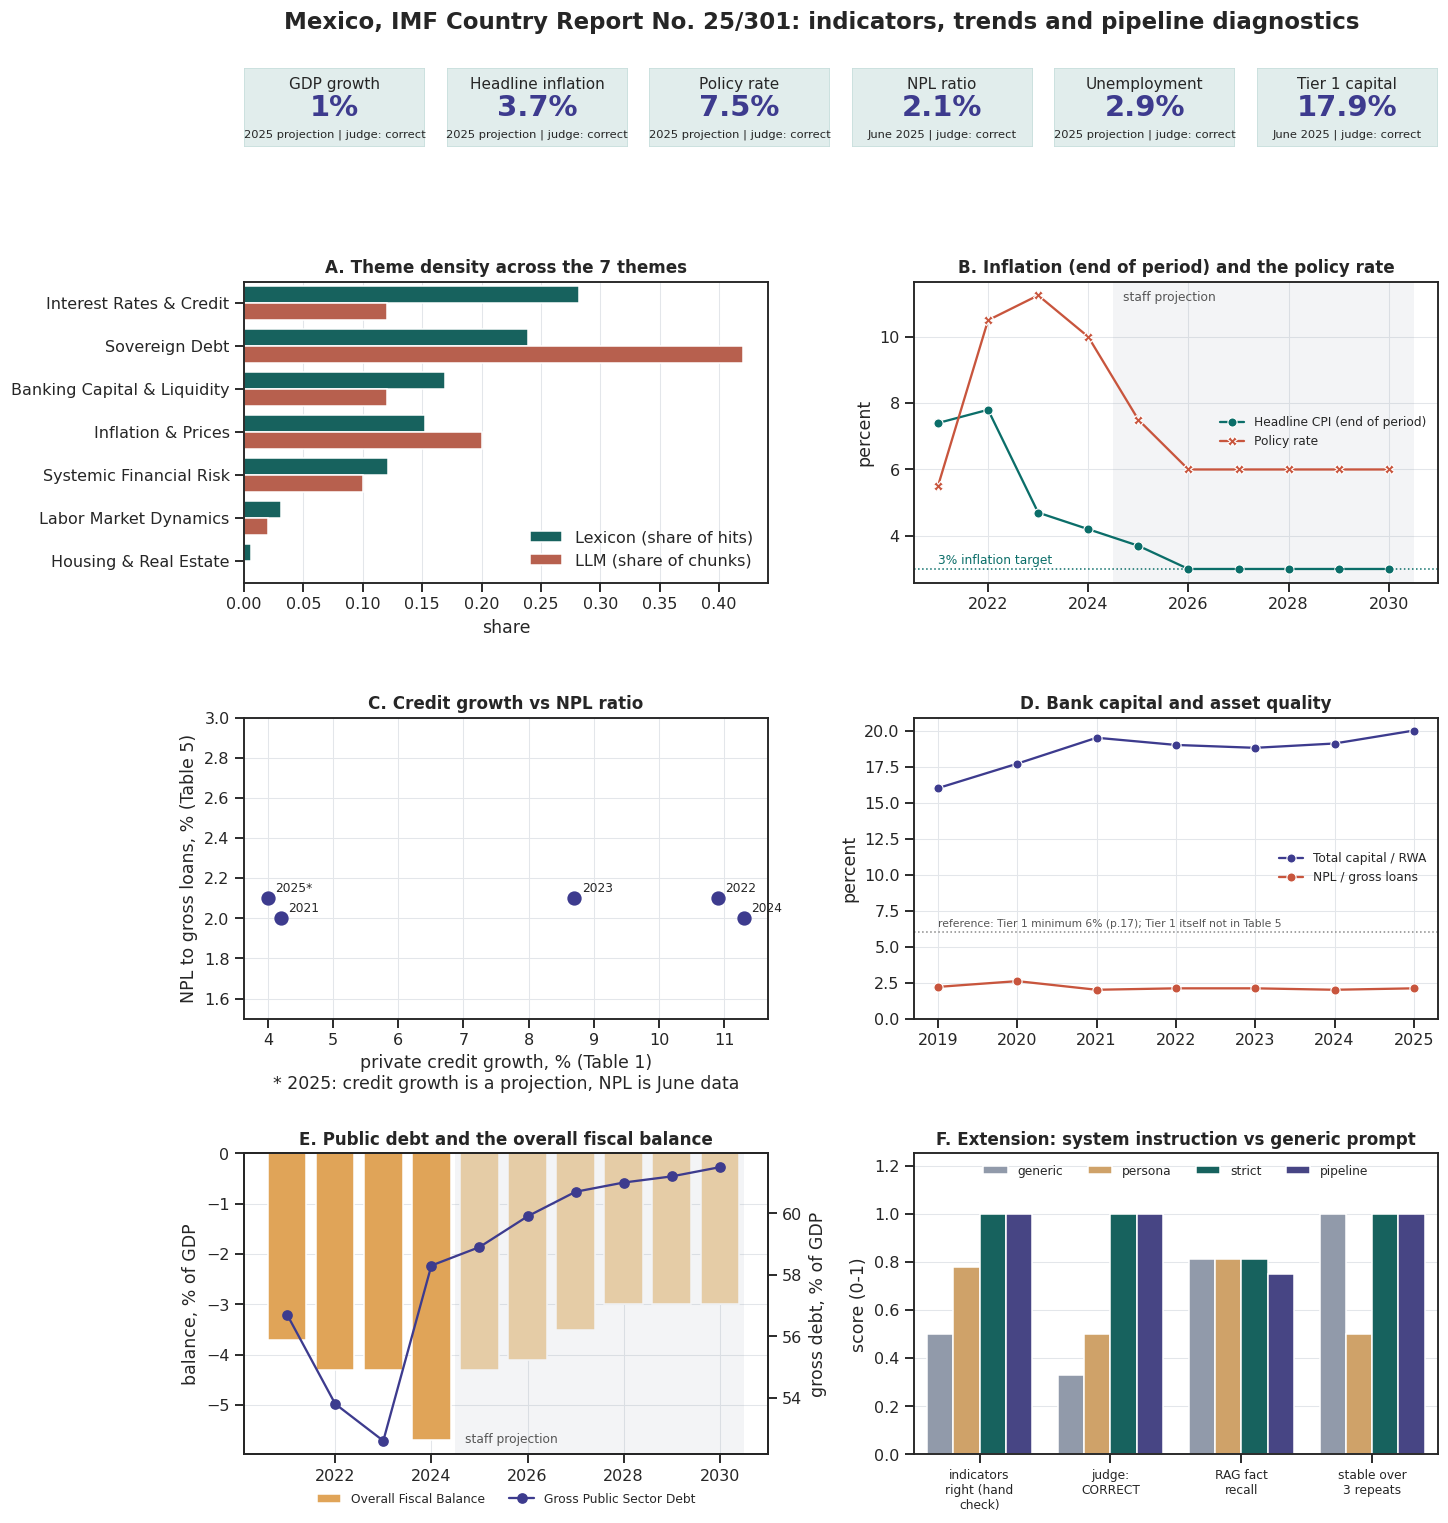

In [25]:
fig = plt.figure(figsize=(14, 15))
grid = fig.add_gridspec(4, 2, height_ratios=[0.26, 1, 1, 1], hspace=0.55, wspace=0.28, top=0.95)
cards = grid[0, :].subgridspec(1, 6, wspace=0.12)
LABELS = {"gdp_growth_forecast_pct": "GDP growth", "headline_inflation_rate_pct": "Headline inflation",
          "central_bank_policy_rate_pct": "Policy rate", "non_performing_loan_ratio": "NPL ratio",
          "unemployment_rate_pct": "Unemployment", "tier_1_capital_ratio": "Tier 1 capital"}
for i, row in enumerate(audit.itertuples()):
    ax = fig.add_subplot(cards[0, i])
    ax.set_axis_off()
    ok = row.judge == "CORRECT"
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, color=PAL["teal"] if ok else PAL["terracotta"],
                               alpha=0.12))
    ax.text(0.5, 0.74, LABELS[row.field], ha="center", fontsize=10, transform=ax.transAxes)
    ax.text(0.5, 0.40, "null" if pd.isna(row.value) else f"{row.value:g}%", ha="center", fontsize=19,
            weight="bold", color=PAL["indigo"], transform=ax.transAxes)
    ax.text(0.5, 0.12, f"{row.period[:26]} | judge: {row.judge.lower()}", ha="center", fontsize=7.5,
            transform=ax.transAxes)
for (name, draw), cell in zip(PANELS.items(), [grid[r, c] for r in (1, 2, 3) for c in (0, 1)]):
    draw(fig.add_subplot(cell))
fig.suptitle(f"Mexico, IMF Country Report No. 25/301: indicators, trends and pipeline diagnostics",
             fontsize=15, weight="bold", y=0.985)
save_panel(fig, "dashboard.png")
plt.show()

**6. Run record: prompts**

This prints every prompt exactly as it was sent.

In [26]:
PROMPTS = {"SYSTEM_STRICT": SYSTEM_STRICT, "SYSTEM_EXTRACT": SYSTEM_EXTRACT, "JUDGE_SYSTEM": JUDGE_SYSTEM,
           "SUMMARY_PROMPT": SUMMARY_PROMPT, "EXEC_PROMPT": EXEC_PROMPT, "THEME_PROMPT": THEME_PROMPT,
           "SV_PROMPT": SV_PROMPT, "EXTRACT_PROMPT": EXTRACT_PROMPT, "AUDIT_PROMPT": AUDIT_PROMPT,
           "TS_PROMPT": TS_PROMPT, "RAG_PROMPT": RAG_PROMPT, "RAG_JUDGE": RAG_JUDGE,
           "GENERIC_EXTRACT": GENERIC_EXTRACT, "GENERIC_RAG": GENERIC_RAG, "PERSONA_SYSTEM": SYSTEMS["persona"]}
write_json(PROMPTS, "prompts.json")
for name, text in PROMPTS.items():
    print(f"--- {name}\n{text}\n")

--- SYSTEM_STRICT
You work for a financial-stability analyst reading an IMF staff report on Mexico. Use only the text you are given. Never add numbers, dates or judgements that are not in it. Keep the report's own figures exactly as printed, with their units and years. If something is not in the text, say so instead of guessing.

--- SYSTEM_EXTRACT
You work for a financial-stability analyst reading an IMF staff report on Mexico. Use only the text you are given. Never add numbers, dates or judgements that are not in it. Keep the report's own figures exactly as printed, with their units and years. If something is not in the text, say so instead of guessing. When a table gives several years, take the current-year (2025) figure, which in this report is a projection or the latest reading, and say so in 'period'. Headline inflation is consumer prices, not core. Unemployment is the national rate. Bank ratios (NPL, Tier 1) are the latest reported date. If the passages do not contain a value, r

**6.2 What this run did**

This counts the model calls and lists the output files.

In [27]:
calls = pd.DataFrame(CALL_LOG)
write_json(calls.to_dict("records"), "call_log.json")
by_step = calls.groupby("step").agg(calls=("model", "size"), live=("live", "sum"), model=("model", "first"),
                                    mean_seconds=("seconds", "mean")).round(1)
print(f"{len(calls)} model calls, {int(calls.live.sum())} live, {len(calls) - int(calls.live.sum())} from cache | "
      f"schema repairs: {len(SCHEMA_REPAIRS)} | backend: {BACKEND}")
display(by_step)
display(pd.DataFrame(LEDGER))
print("files:", sorted(p.name for p in OUT_JSON.glob("*.json")))

166 model calls, 0 live, 166 from cache | schema repairs: 7 | backend: colab


,calls,live,model,mean_seconds
step,,,,
exec_judge,1,0,google/gemini-3.1-pro-preview,10.9
exec_summary,1,0,google/gemini-3.8-flash,34.2
ext_generic_indicators,3,0,google/gemini-3.8-flash,17.7
ext_generic_indicators_audit,3,0,google/gemini-3.1-pro-preview,29.3
ext_generic_indicators_audit:repair,3,0,google/gemini-3.1-pro-preview,27.1
ext_generic_rag,9,0,google/gemini-3.8-flash,5.7
ext_generic_rag_judge,9,0,google/gemini-3.1-pro-preview,3.1
ext_persona_indicators,3,0,google/gemini-3.8-flash,23.7
ext_persona_indicators_audit,3,0,google/gemini-3.1-pro-preview,28.6


,step,file,seconds,items
0,read_pdf,pages.json,8.55,54
1,split_sections,sections.json,0.06,37
2,make_chunks,chunks.json,2.06,114
3,summarise_sections,section_summaries.json,0.03,15
4,executive_summary,executive_summary.json,0.00,2
5,theme_counts,theme_counts.json,0.25,15
6,llm_theme_labels,theme_chunk_labels.json,0.01,60
7,strengths_and_vulnerabilities,strengths_vulnerabilities.json,0.02,1
8,time_series,time_series.json,0.02,10
9,run_extension,extension_runs.json,4.95,48


files: ['call_log.json', 'chunks.json', 'clean_text.json', 'core_indicators.json', 'core_indicators_evidence.json', 'dashboard_data.json', 'executive_summary.json', 'extension_comparison.json', 'extension_runs.json', 'judge_audit.json', 'ocr_hand_check.json', 'pages.json', 'prompts.json', 'rag_results.json', 'section_summaries.json', 'sections.json', 'strengths_vulnerabilities.json', 'theme_chunk_labels.json', 'theme_counts.json', 'themes.json', 'time_series.json']
